# India Digital Payments: Channel Analysis

**Author: Mansi Saxena**

[LinkedIn](https://www.linkedin.com/in/mansi-saxena-049102362) | [GitHub](https://github.com/050804mansi) | [Email](mailto:mansi53245@gmail.com)

This notebook compares annual RBI payment-mode aggregates for FY 2021-22 through FY 2025-26. The mode-level rows are not a complete additive breakdown; use the RBI aggregate totals for market-wide shares.

## 1. Load the data and calculate growth

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'Data').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'Data'
modes = pd.read_csv(DATA / 'annual_payment_mode_statistics.csv')
totals = pd.read_csv(DATA / 'annual_payment_system_totals.csv')
modes = modes.sort_values(['Payment_Mode', 'Financial_Year']).copy()
modes['Volume_Index'] = modes.groupby('Payment_Mode').Transaction_Volume_Lakh.transform(lambda s: s / s.iloc[0] * 100)
modes['Estimated_Average_Ticket_INR'] = modes.Transaction_Value_Lakh_Crore / modes.Transaction_Volume_Lakh * 10_000_000
upi = modes[modes.Payment_Mode.eq('UPI')][['Financial_Year', 'Transaction_Volume_Lakh']]
totals = totals.merge(upi, on='Financial_Year', validate='one_to_one').rename(columns={'Transaction_Volume_Lakh': 'UPI_Volume_Lakh'})
totals['UPI_Share_Pct'] = totals.UPI_Volume_Lakh / totals.Total_Retail_Volume_Lakh * 100
display(modes.groupby('Payment_Mode').tail(1).sort_values('Transaction_Volume_Lakh', ascending=False))

,Financial_Year,Payment_Mode,Mode_Group,Transaction_Volume_Lakh,Transaction_Value_Lakh_Crore,Volume_Index,Estimated_Average_Ticket_INR
9,2025-26,UPI,Retail_Credit,2416169,314.2,525.755884,1.300406e+03
14,2025-26,NEFT,Retail_Credit,100996,502.3,249.946791,4.973464e+04
34,2025-26,Prepaid_Instruments,Retail_PPI,98699,2.9,150.037244,2.938226e+02
24,2025-26,Credit_Cards,Retail_Card,60238,23.6,268.931649,3.917793e+03
19,2025-26,IMPS,Retail_Credit,49431,76.7,106.018231,1.551658e+04
29,2025-26,Debit_Cards,Retail_Card,12802,4.5,32.505586,3.515076e+03
4,2025-26,RTGS,Large_Value,3500,2273.7,168.431184,6.496286e+06


## 2. Compare relative volume growth

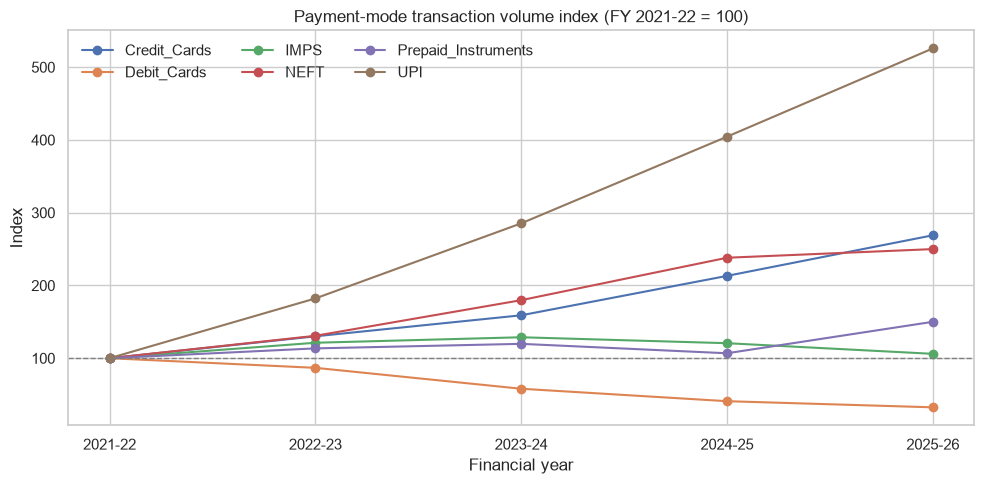

In [2]:
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 5))
for mode, part in modes.groupby('Payment_Mode'):
    if mode == 'RTGS':
        continue
    ax.plot(part.Financial_Year, part.Volume_Index, marker='o', label=mode)
ax.axhline(100, color='grey', ls='--', lw=1)
ax.set(title='Payment-mode transaction volume index (FY 2021-22 = 100)', ylabel='Index', xlabel='Financial year')
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 3. Track UPI's share of retail payment volume

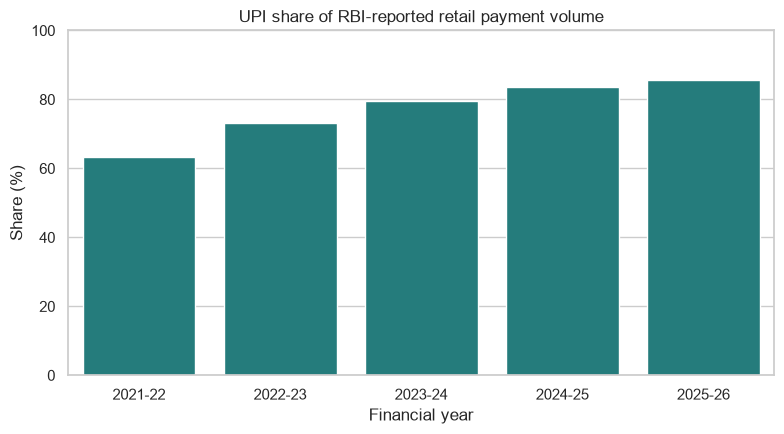

,Financial_Year,UPI_Volume_Lakh,Total_Retail_Volume_Lakh,UPI_Share_Pct
0,2021-22,459561,724689,63.414927
1,2022-23,837144,1144065,73.172766
2,2023-24,1311295,1648234,79.557575
3,2024-25,1858660,2222885,83.614762
4,2025-26,2416169,2819536,85.693852


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=totals, x='Financial_Year', y='UPI_Share_Pct', color='#168b8b', ax=ax)
ax.set(title='UPI share of RBI-reported retail payment volume', ylabel='Share (%)', xlabel='Financial year')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()
display(totals[['Financial_Year', 'UPI_Volume_Lakh', 'Total_Retail_Volume_Lakh', 'UPI_Share_Pct']])

## 4. Compare estimated average ticket size

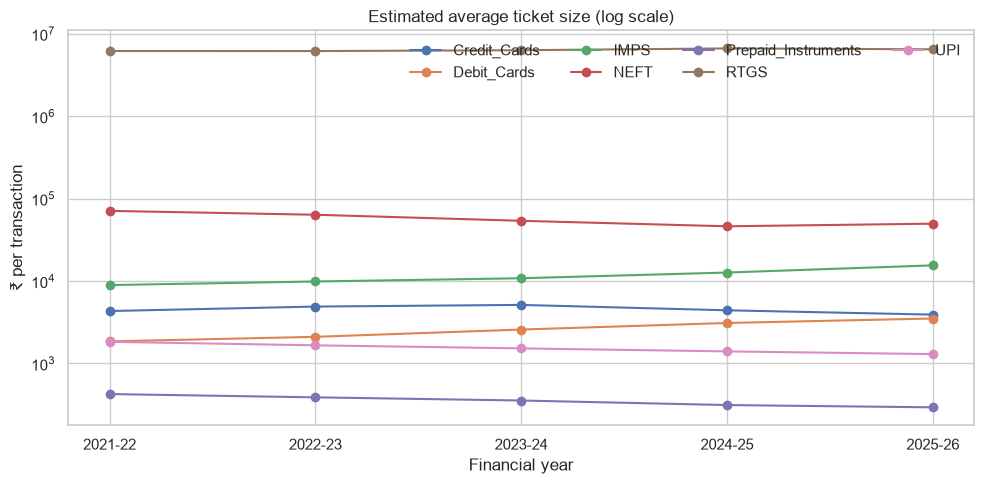

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for mode, part in modes.groupby('Payment_Mode'):
    ax.plot(part.Financial_Year, part.Estimated_Average_Ticket_INR, marker='o', label=mode)
ax.set_yscale('log')
ax.set(title='Estimated average ticket size (log scale)', ylabel='₹ per transaction', xlabel='Financial year')
ax.legend(frameon=False, ncol=4)
plt.tight_layout()
plt.show()

## 5. Interpretation and caveats

Compare the indexed chart for relative growth and the share chart for UPI's place in total retail volume. RTGS is a large-value system. Average ticket sizes are estimates from rounded annual totals. Five annual observations support a descriptive comparison, not monthly seasonality analysis, causal claims or forecasts. See `DATA_SOURCES.md` for attribution and units.